# 🚨 Chapter 11: Novelty and Outlier Detection
**Book Reference:** *scikit-learn Cookbook, Third Edition*

---
## 1. Introduction
In many operational applications (such as cybersecurity or fraud detection), the core objective is to flag data points that deviate significantly from standard normal patterns. By convention, `scikit-learn` assigns a label of **1 for inliers (normal data)** and **-1 for outliers (anomalies)**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor

%matplotlib inline
np.random.seed(42)

## 2. Isolation Forest (Outlier Detection)
This algorithm is highly fast and computationally efficient. Instead of profiling normal points, it isolates anomalous observations by randomly partitioning features. Outliers are isolated much faster down the tree structure, requiring fewer splits.

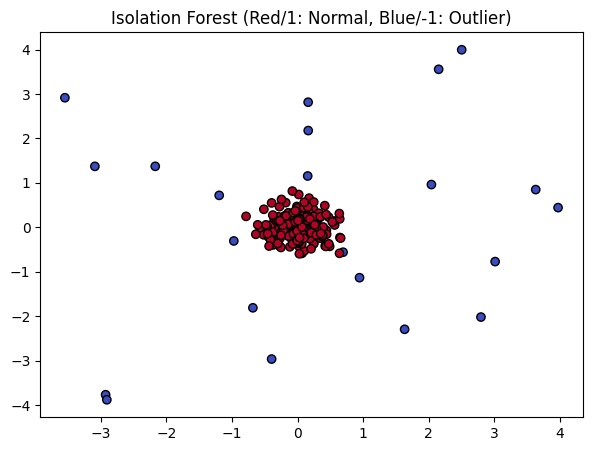

In [2]:
# Simulate Normal Baseline Data
X_normal = 0.3 * np.random.randn(200, 2)
# Simulate Outlier Data
X_outliers = np.random.uniform(low=-4, high=4, size=(20, 2))
X_train = np.r_[X_normal, X_outliers]

# Train Isolation Forest (Assuming a 10% expected contamination rate)
iso_forest = IsolationForest(contamination=0.1, random_state=42)
y_pred_iso = iso_forest.fit_predict(X_train)

plt.figure(figsize=(7, 5))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_pred_iso, cmap='coolwarm', edgecolor='k')
plt.title('Isolation Forest (Red/1: Normal, Blue/-1: Outlier)')
plt.show()

## 3. One-Class SVM (Novelty Detection)
This approach is ideal when your available training dataset is entirely clean and clear of anomalous entries. The model fits a tight decision boundary around the known normal space and evaluates whether incoming new test observations fall outside of that boundary envelope.

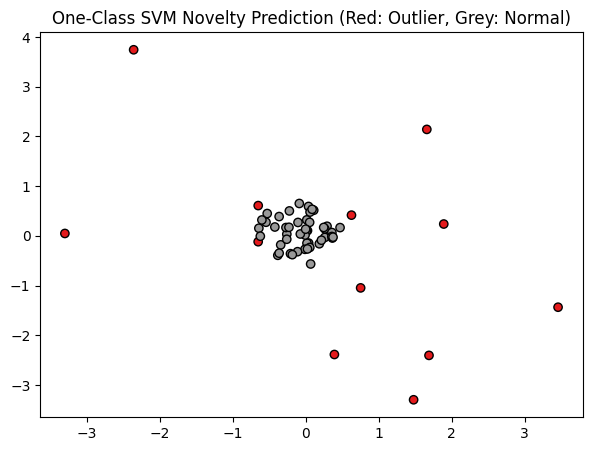

In [3]:
# Trained EXCLUSIVELY on clean, normal data instances
oc_svm = OneClassSVM(kernel='rbf', gamma='auto', nu=0.05)
oc_svm.fit(X_normal)

# Mixed Novel Test Evaluation Set
X_test_new = np.r_[0.3 * np.random.randn(50, 2), np.random.uniform(low=-4, high=4, size=(10, 2))]
y_pred_svm = oc_svm.predict(X_test_new)

plt.figure(figsize=(7, 5))
plt.scatter(X_test_new[:, 0], X_test_new[:, 1], c=y_pred_svm, cmap='Set1', edgecolor='k')
plt.title('One-Class SVM Novelty Prediction (Red: Outlier, Grey: Normal)')
plt.show()